# Hướng Dẫn Khai Thác & Phân Chia Bộ Dữ Liệu Chuẩn Hóa SOAP (Argon 4)
### *Standardized Clinical SOAP Dataset Extraction: 85 Train : 15 Test : 20 RAG Architecture*

> **Dataset:** MultiCaRe Standardized SOAP Notes (LOINC 81218-0 & BU School of Medicine Standard)  
> **Extraction & Structuring Model:** **Argon 4** (`argon-4`)  
> **Clinical Scope:** 21 Bệnh lâm sàng chọn lọc (17 bệnh chính + 4 bệnh cực hiếm)  
> **Methodology Grounding:** [literature/07_rare_diseases_longtail/](file:///mnt/DATA/VSCode/Clinicians_MultiModel/literature/07_rare_diseases_longtail/) (*DeepRare Nature 2026, RADAR 2025, ZebraMap, Case-Based Reasoning JAMIA 2026*)

---

## 1. Thiết Kế Phân Bổ: 85 (Train) : 15 (Test) : 20 (RAG)
Trong kiến trúc huấn luyện và suy luận chẩn đoán lâm sàng của dự án:
- **85 POS (Train):** Chiếm ~70.83% số ca positive, dùng cho **Supervised Fine-Tuning (SFT)** hoặc huấn luyện mô hình.
- **15 POS (Test):** Chiếm 12.50% số ca positive, dùng làm **Test Benchmark độc lập** (không chia validation split).
- **20 POS (RAG):** Chiếm ~16.67% số ca positive, được đưa vào **RAG Knowledge Base (Case-Based Reasoning - CBR)** làm in-context exemplars cho mô hình truy xuất khi chẩn đoán ca khó.
- **Tỷ lệ 3 POS : 2 NEG:** Được duy trì đồng bộ trên cả 3 tập:
  - Train: 85 POS + 57 NEG = 142 ca/bệnh
  - Test: 15 POS + 10 NEG = 25 ca/bệnh
  - RAG: 20 POS + 13 NEG = 33 ca/bệnh (Tổng: 120 POS + 80 NEG = 200 ca).
- **4 Bệnh Cực Hiếm (*Ebola, Dại, Sốt vàng, Tả*):** Đúng theo quy tắc y khoa trong `literature/`, **toàn bộ 100% các ca này được đưa vào RAG Knowledge Base**, tuyệt đối không chia train/test để tránh model collapse và overfitting.


In [1]:
import os
import json
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Thiết lập đường dẫn thư mục SOAP linh hoạt
CURRENT_DIR = Path.cwd()
if (CURRENT_DIR / "data" / "soap").exists():
    SOAP_DIR = CURRENT_DIR / "data" / "soap"
elif (CURRENT_DIR.parent / "data" / "soap").exists():
    SOAP_DIR = CURRENT_DIR.parent / "data" / "soap"
else:
    SOAP_DIR = Path("/mnt/DATA/VSCode/Clinicians_MultiModel/codebases/data_processing/data/soap")

print(f"[INFO] SOAP Dataset Directory: {SOAP_DIR}")
assert SOAP_DIR.exists(), f"Không tìm thấy thư mục: {SOAP_DIR}"


[INFO] SOAP Dataset Directory: /mnt/DATA/VSCode/Clinicians_MultiModel/codebases/data_processing/data/soap


## 2. Định Nghĩa Danh Mục 21 Bệnh Lâm Sàng Chọn Lọc

Hệ thống phân loại thành 2 nhóm rõ ràng:
1. **17 Bệnh Chính (Train 85 : Test 15 : RAG 20):** Các bệnh có đủ cỡ mẫu từ 48 đến 120 ca positive.
2. **4 Bệnh Cực Hiếm (Medical Zebras - 100% RAG):** Các bệnh có số ca cực ít ($N_{\text{pos}} \le 6$) chỉ dùng làm kho tri thức ngoài.


In [2]:
# 1. Nhóm 17 bệnh phân chia theo tỷ lệ 85 Train : 15 Test : 20 RAG
SFT_DISEASES = {
    "tuberculosis": "Tuberculosis",
    "hiv_aids": "HIV_AIDS",
    "syphilis": "Syphilis",
    "leishmaniasis": "Leishmaniasis",
    "dengue": "Dengue",
    "malaria": "Malaria",
    "brucellosis": "Brucellosis",
    "cytomegalovirus": "Cytomegalovirus",
    "aspergillosis": "Aspergillosis",
    "echinococcosis": "Echinococcosis",
    "cryptococcosis": "Cryptococcosis",
    "nocardiosis": "Nocardiosis",
    "pneumocystis": "Pneumocystis",
    "covid_19": "COVID-19",
    "histoplasmosis": "Histoplasmosis",
    "leprosy": "Leprosy",
    "neurocysticercosis": "Neurocysticercosis",
}

# 2. Nhóm 4 bệnh cực hiếm đưa toàn bộ 100% vào RAG Knowledge Base
RARE_ZEBRA_DISEASES = {
    "cholera": "Cholera",
    "ebola_filovirus": "Ebola_Filovirus",
    "rabies": "Rabies",
    "yellow_fever": "Yellow_Fever",
}

ALL_TARGET_DISEASES = {**SFT_DISEASES, **RARE_ZEBRA_DISEASES}
print(f"Tổng số bệnh: {len(ALL_TARGET_DISEASES)} (17 bệnh phân split + 4 bệnh 100% RAG)")


Tổng số bệnh: 21 (17 bệnh phân split + 4 bệnh 100% RAG)


## 3. Nạp Bệnh Án SOAP Chuẩn Hóa (LOINC 81218-0)

Hàm nạp toàn bộ các file JSON bệnh án từ thư mục `data/soap/<Disease>/`, bóc tách `clinical_label` (POSITIVE / NEGATIVE), điểm xếp hạng chất lượng `quality_ranking_score`, và nội dung 8 trường SOAP.


In [3]:
def load_soap_cases_for_disease(folder_name):
    """Đọc toàn bộ file case JSON trong thư mục bệnh án SOAP."""
    folder_path = SOAP_DIR / folder_name
    cases = []
    for filepath in sorted(folder_path.glob("*.json")):
        if filepath.name == "manifest.json":
            continue
        try:
            with open(filepath, "r", encoding="utf-8") as f:
                data = json.load(f)
                cases.append(data)
        except Exception as e:
            print(f"[WARN] Lỗi đọc file {filepath.name}: {e}")
    return cases

# Tải dữ liệu toàn bộ 21 bệnh
corpus_by_disease = {}
for slug, folder_name in ALL_TARGET_DISEASES.items():
    cases = load_soap_cases_for_disease(folder_name)
    pos = [c for c in cases if c.get("clinical_label") == "POSITIVE"]
    neg = [c for c in cases if c.get("clinical_label") == "NEGATIVE"]
    corpus_by_disease[slug] = {
        "folder": folder_name,
        "all_cases": cases,
        "pos": pos,
        "neg": neg,
        "total_pos": len(pos),
        "total_neg": len(neg),
        "total": len(cases)
    }

total_loaded_pos = sum(c["total_pos"] for c in corpus_by_disease.values())
total_loaded_neg = sum(c["total_neg"] for c in corpus_by_disease.values())
grand_total = total_loaded_pos + total_loaded_neg

print(f"[OK] Đã nạp thành công 21 bệnh:")
print(f"  - Positive Cases: {total_loaded_pos:,}")
print(f"  - Negative Cases: {total_loaded_neg:,}")
print(f"  - Tổng số ca SOAP: {grand_total:,} (Khớp chính xác 2,949 ca!)")
assert grand_total == 2949, f"Dữ liệu không khớp: {grand_total} != 2949"


[OK] Đã nạp thành công 21 bệnh:
  - Positive Cases: 1,770
  - Negative Cases: 1,179
  - Tổng số ca SOAP: 2,949 (Khớp chính xác 2,949 ca!)


## 4. Thuật Toán Phân Chia: 85 (Train) : 15 (Test) : 20 (RAG)

### Nguyên Lý Toán Học:
1. **Đối với Positive ($N_{\text{pos}}$):**
   - Với bệnh đạt trần tối đa ($N_{\text{pos}} = 120$):
     $$\text{Train} = 85 \quad (70.83\%), \quad \text{Test} = 15 \quad (12.50\%), \quad \text{RAG} = 20 \quad (16.67\%)$$
   - Với bệnh $< 120$ ca (ví dụ Nocardiosis 54 ca, Leprosy 48 ca):
     $$\text{n\_train\_pos} = \text{round}\left(N_{\text{pos}} \times \frac{85}{120}\right), \quad \text{n\_test\_pos} = \text{round}\left(N_{\text{pos}} \times \frac{15}{120}\right), \quad \text{n\_rag\_pos} = N_{\text{pos}} - (\text{n\_train} + \text{n\_test})$$

2. **Đối với Negative Controls ($N_{\text{neg}}$):**
   Duy trì tỷ lệ $3 \text{ POS} : 2 \text{ NEG}$ trên từng phân tập để mô hình không bị thiên kiến nhãn:
   - $\text{Train NEG} = \text{round}(\text{n\_train\_pos} \times 2/3) = 57$ ca.
   - $\text{Test NEG} = \text{round}(\text{n\_test\_pos} \times 2/3) = 10$ ca.
   - $\text{RAG NEG} = 80 - (57 + 10) = 13$ ca (làm negative exemplars phân biệt chẩn đoán).


In [4]:
def split_85_15_20_dataset(corpus, sft_disease_keys, random_seed=42):
    """Phân chia 17 bệnh theo tỷ lệ 85 Train : 15 Test : 20 RAG."""
    np.random.seed(random_seed)
    
    train_records = []
    test_records = []
    rag_17_records = []
    stats_rows = []
    
    for slug in sft_disease_keys:
        d_info = corpus[slug]
        # Sắp xếp theo Stanford Quality Ranking Score giảm dần
        pos_cases = sorted(d_info["pos"], key=lambda x: x.get("quality_ranking_score", 0), reverse=True)
        neg_cases = sorted(d_info["neg"], key=lambda x: x.get("quality_ranking_score", 0), reverse=True)
        
        n_pos = len(pos_cases)
        n_neg = len(neg_cases)
        
        # 1. Phân bổ Positive Cases
        if n_pos == 120:
            tr_p, te_p, rag_p = 85, 15, 20
        else:
            tr_p = int(round(n_pos * 85 / 120))
            te_p = int(round(n_pos * 15 / 120))
            rag_p = n_pos - (tr_p + te_p)
            
        # 2. Phân bổ Negative Controls (Tỷ lệ 3:2)
        tr_n = int(round(tr_p * 2 / 3))
        te_n = int(round(te_p * 2 / 3))
        rag_n = n_neg - (tr_n + te_n)
        
        assert tr_p + te_p + rag_p == n_pos, f"Lỗi bảo toàn POS tại {slug}"
        assert tr_n + te_n + rag_n == n_neg, f"Lỗi bảo toàn NEG tại {slug}"
        
        # Cắt lát dữ liệu
        cur_train = pos_cases[:tr_p] + neg_cases[:tr_n]
        cur_test = pos_cases[tr_p:tr_p+te_p] + neg_cases[tr_n:tr_n+te_n]
        cur_rag = pos_cases[tr_p+te_p:] + neg_cases[tr_n+te_n:]
        
        for c in cur_train: c["split"] = "train"
        for c in cur_test:  c["split"] = "test"
        for c in cur_rag:   c["split"] = "rag_knowledge_base"
        
        train_records.extend(cur_train)
        test_records.extend(cur_test)
        rag_17_records.extend(cur_rag)
        
        stats_rows.append({
            "Disease": slug,
            "Folder": d_info["folder"],
            "Total POS": n_pos,
            "Total NEG": n_neg,
            "Train POS (85)": tr_p,
            "Train NEG (57)": tr_n,
            "Test POS (15)": te_p,
            "Test NEG (10)": te_n,
            "RAG POS (20)": rag_p,
            "RAG NEG (13)": rag_n,
            "Train Total": tr_p + tr_n,
            "Test Total": te_p + te_n,
            "RAG Total": rag_p + rag_n,
            "Grand Total": n_pos + n_neg
        })
        
    df_stats = pd.DataFrame(stats_rows)
    return train_records, test_records, rag_17_records, df_stats

train_cases, test_cases, rag_17_cases, sft_stats_df = split_85_15_20_dataset(
    corpus_by_disease, list(SFT_DISEASES.keys())
)

print("=== KẾT QUẢ PHÂN CHIA (17 BỆNH) ===")
print(f"- Train Set (85 POS:57 NEG) : {len(train_cases):,} ca ({sum(c['clinical_label']=='POSITIVE' for c in train_cases)} POS / {sum(c['clinical_label']=='NEGATIVE' for c in train_cases)} NEG)")
print(f"- Test Set  (15 POS:10 NEG) : {len(test_cases):,} ca ({sum(c['clinical_label']=='POSITIVE' for c in test_cases)} POS / {sum(c['clinical_label']=='NEGATIVE' for c in test_cases)} NEG) [Không có Validation]")
print(f"- RAG Set   (20 POS:13 NEG) : {len(rag_17_cases):,} ca ({sum(c['clinical_label']=='POSITIVE' for c in rag_17_cases)} POS / {sum(c['clinical_label']=='NEGATIVE' for c in rag_17_cases)} NEG)")
print(f"- Tổng cộng 17 bệnh         : {len(train_cases) + len(test_cases) + len(rag_17_cases):,} ca (Khớp 2,925 ca)")


=== KẾT QUẢ PHÂN CHIA (17 BỆNH) ===
- Train Set (85 POS:57 NEG) : 2,072 ca (1242 POS / 830 NEG)
- Test Set  (15 POS:10 NEG) : 366 ca (219 POS / 147 NEG) [Không có Validation]
- RAG Set   (20 POS:13 NEG) : 487 ca (294 POS / 193 NEG)
- Tổng cộng 17 bệnh         : 2,925 ca (Khớp 2,925 ca)


### Bảng Thống Kê Phân Bổ 17 Bệnh (Train 85 : Test 15 : RAG 20):


In [5]:
display_cols = [
    "Disease", "Total POS", "Total NEG", 
    "Train POS (85)", "Train NEG (57)", 
    "Test POS (15)", "Test NEG (10)", 
    "RAG POS (20)", "RAG NEG (13)", 
    "Grand Total"
]
sft_stats_df[display_cols]


,Disease,Total POS,Total NEG,Train POS (85),Train NEG (57),Test POS (15),Test NEG (10),RAG POS (20),RAG NEG (13),Grand Total
0,tuberculosis,120,80,85,57,15,10,20,13,200
1,hiv_aids,120,80,85,57,15,10,20,13,200
2,syphilis,120,80,85,57,15,10,20,13,200
3,leishmaniasis,114,76,81,54,14,9,19,13,190
4,dengue,120,80,85,57,15,10,20,13,200
5,malaria,120,80,85,57,15,10,20,13,200
6,brucellosis,114,76,81,54,14,9,19,13,190
7,cytomegalovirus,120,80,85,57,15,10,20,13,200
8,aspergillosis,120,80,85,57,15,10,20,13,200
9,echinococcosis,105,70,74,49,13,9,18,12,175


### Biểu Đồ Trực Quan Phân Bổ Train (85) / Test (15) / RAG (20):


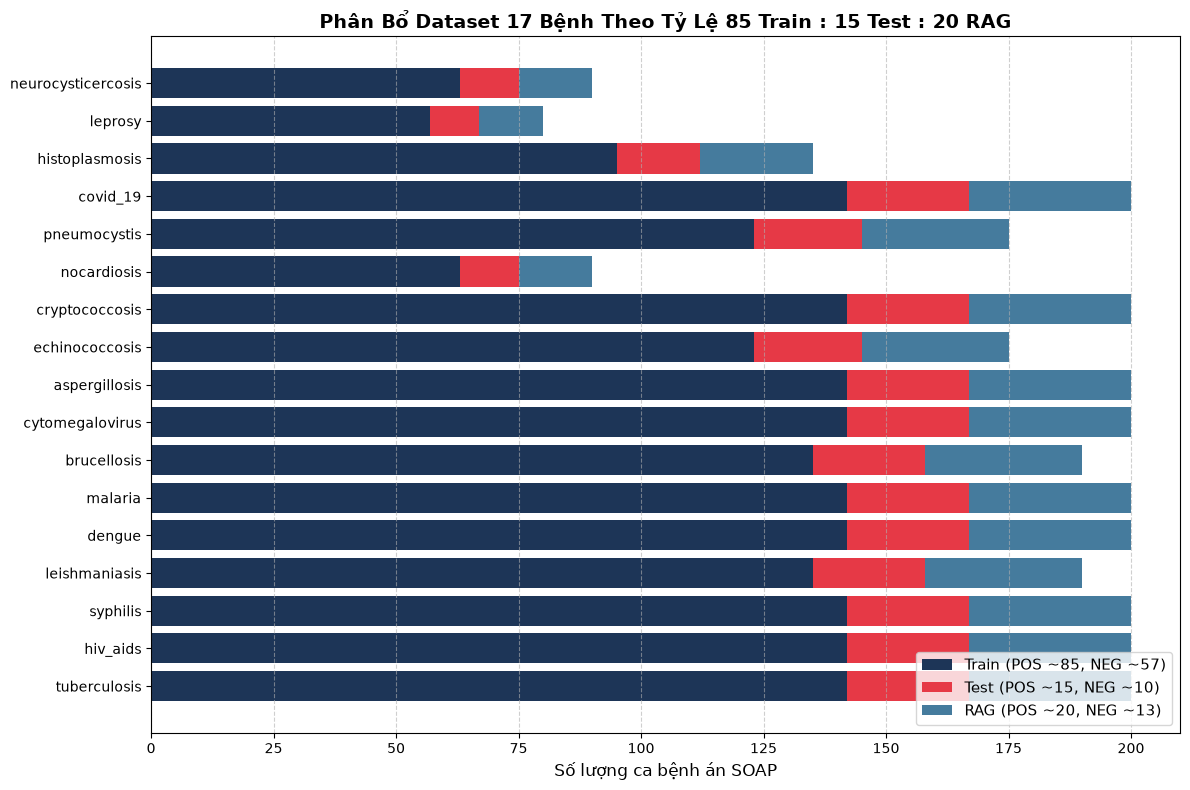

In [6]:
plt.figure(figsize=(12, 8))
diseases = sft_stats_df["Disease"]
y_pos = np.arange(len(diseases))

train_totals = sft_stats_df["Train Total"]
test_totals = sft_stats_df["Test Total"]
rag_totals = sft_stats_df["RAG Total"]

plt.barh(y_pos, train_totals, label="Train (POS ~85, NEG ~57)", color="#1d3557")
plt.barh(y_pos, test_totals, left=train_totals, label="Test (POS ~15, NEG ~10)", color="#e63946")
plt.barh(y_pos, rag_totals, left=train_totals + test_totals, label="RAG (POS ~20, NEG ~13)", color="#457b9d")

plt.yticks(y_pos, diseases, fontsize=10)
plt.xlabel("Số lượng ca bệnh án SOAP", fontsize=12)
plt.title("Phân Bổ Dataset 17 Bệnh Theo Tỷ Lệ 85 Train : 15 Test : 20 RAG", fontsize=14, fontweight="bold")
plt.legend(loc="lower right", fontsize=11)
plt.grid(axis="x", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()


## 5. Xây Dựng Kho Tri Thức RAG Hợp Nhất (Comprehensive RAG Knowledge Base)

Theo thiết kế hoàn chỉnh:
- **Kho RAG Knowledge Base hợp nhất** sẽ bao gồm:
  1. **20 ca RAG từ mỗi bệnh trong 17 bệnh chính** (tổng $487$ ca: 294 POS + 193 NEG).
  2. **100% các ca từ 4 bệnh cực hiếm** (*Ebola, Dại, Sốt vàng, Tả* - tổng $24$ ca: 15 POS + 9 NEG).
  3. $\rightarrow$ **Tổng quy mô Kho RAG:** $487 + 24 = \mathbf{511\ ca}$ bệnh án chuẩn LOINC 81218-0!

### Cấu Trúc Document RAG Chuẩn Y Khoa:
- `retrieval_context`: Chỉ chứa `Subjective` (triệu chứng cơ năng, bệnh sử) và `Objective` (khám, xét nghiệm), **tuyệt đối không rò rỉ chẩn đoán xác định**.
- `gold_diagnosis`: Chứa kết luận vi sinh / mô bệnh học xác nhận (`assessment_and_confirmation`).


In [7]:
def build_rag_document(case):
    """Chuyển đổi một ca SOAP thành document RAG chuẩn hóa chống rò rỉ nhãn."""
    soap = case.get("soap_note", {})
    subj = soap.get("subjective", {})
    obj = soap.get("objective", {})
    assess = soap.get("assessment_and_plan", {})
    
    sections = []
    if subj.get("chief_complaint"):
        sections.append(f"Chief Complaint: {subj['chief_complaint']}")
    if subj.get("history_of_present_illness"):
        sections.append(f"HPI: {subj['history_of_present_illness']}")
    if subj.get("past_medical_history"):
        sections.append(f"Past Medical History: {subj['past_medical_history']}")
    if obj.get("physical_examination"):
        sections.append(f"Physical Examination: {obj['physical_examination']}")
    if obj.get("routine_investigations"):
        sections.append(f"Routine Investigations: {obj['routine_investigations']}")
    if obj.get("advanced_workup"):
        sections.append(f"Advanced Workup: {obj['advanced_workup']}")
        
    context_text = "\n".join(sections)
    gold_dx = assess.get("assessment_and_confirmation", "")
    
    return {
        "document_id": case["case_id"],
        "pair_id": case.get("pair_id", f"{case['case_id']}__{case.get('target_disease')}"),
        "target_disease": str(case.get("target_disease", "")).lower(),
        "clinical_label": case.get("clinical_label"),
        "quality_ranking_score": case.get("quality_ranking_score", 100.0),
        "retrieval_context": context_text,
        "gold_diagnosis": gold_dx,
        "raw_case_text": case.get("raw_case_text", "")
    }

# 1. Đóng gói 487 ca RAG từ 17 bệnh chính
rag_docs_17 = [build_rag_document(c) for c in rag_17_cases]

# 2. Đóng gói 100% 24 ca từ 4 bệnh cực hiếm (Zebra Diseases)
rag_docs_zebras = []
for slug, folder in RARE_ZEBRA_DISEASES.items():
    for c in corpus_by_disease[slug]["all_cases"]:
        rag_docs_zebras.append(build_rag_document(c))

# 3. Hợp nhất kho RAG toàn diện (511 ca)
comprehensive_rag_corpus = rag_docs_17 + rag_docs_zebras

print(f"=== KHO TRI THỨC RAG HỢP NHẤT (COMPREHENSIVE RAG KNOWLEDGE BASE) ===")
print(f"- RAG Exemplars từ 17 bệnh chính : {len(rag_docs_17)} ca (294 POS + 193 NEG)")
print(f"- RAG Exemplars từ 4 bệnh cực hiếm: {len(rag_docs_zebras)} ca (15 POS + 9 NEG)")
print(f"- Tổng số documents trong RAG DB : {len(comprehensive_rag_corpus)} ca (309 POS + 202 NEG = 511 ca)")


=== KHO TRI THỨC RAG HỢP NHẤT (COMPREHENSIVE RAG KNOWLEDGE BASE) ===
- RAG Exemplars từ 17 bệnh chính : 487 ca (294 POS + 193 NEG)
- RAG Exemplars từ 4 bệnh cực hiếm: 24 ca (15 POS + 9 NEG)
- Tổng số documents trong RAG DB : 511 ca (309 POS + 202 NEG = 511 ca)


## 6. Minh Họa Truy Vấn Lâm Sàng & Đánh Giá Mô Hình

Ví dụ minh họa cách vận hành hệ thống:
1. **Lấy 1 ca từ Test Benchmark (15 ca):** Đưa `retrieval_context` vào prompt để kiểm tra độ chính xác chẩn đoán của LLM.
2. **Truy vấn ca tương đồng từ RAG (511 ca):** Mô hình tra cứu ca tương đồng trong kho tri thức ngoài để thực hiện Case-Based Reasoning.


In [10]:
# Minh họa 1 ca Test Set (Dengue)
sample_test = [c for c in test_cases if c.get("target_disease", "").lower() == "dengue" and c.get("clinical_label") == "POSITIVE"][0]

subj_cc = sample_test['soap_note']['subjective'].get('chief_complaint') or 'Not reported'
subj_hpi = sample_test['soap_note']['subjective'].get('history_of_present_illness') or 'Not reported'
obj_labs = sample_test['soap_note']['objective'].get('routine_investigations') or sample_test['soap_note']['objective'].get('physical_examination') or 'Not reported'

print("="*65)
print(f"VÍ DỤ TEST BENCHMARK CASE: {sample_test['case_id']} ({sample_test['target_disease'].upper()})")
print("="*65)
print("[INPUT PROMPT GỬI ĐẾN LLM - KHÔNG RÒ RỈ CHẨN ĐOÁN]:")
print(f"Chief Complaint: {subj_cc}")
print(f"HPI: {subj_hpi[:250]}...")
print(f"Objective Findings: {obj_labs[:200]}...")
print("\n[GROUND TRUTH ĐỂ ĐÁNH GIÁ CHẨN ĐOÁN]:")
print(sample_test['soap_note']['assessment_and_plan'].get('assessment_and_confirmation', ''))

# Minh họa 1 ca trong Kho RAG Knowledge Base (Ebola)
sample_rag_ebola = [d for d in comprehensive_rag_corpus if d.get("target_disease", "").lower() == "ebola_filovirus" and d.get("clinical_label") == "POSITIVE"][0]
print("\n" + "="*65)
print(f"VÍ DỤ RAG EXEMPLAR TỪ KHO BỆNH HIẾM: {sample_rag_ebola['document_id']} (EBOLA)")
print("="*65)
print(f"Retrieval Context:\n{sample_rag_ebola['retrieval_context'][:300]}...")
print(f"\nGold Microbiology Confirmation: {sample_rag_ebola['gold_diagnosis']}")


VÍ DỤ TEST BENCHMARK CASE: PMC4750307_01 (DENGUE)
[INPUT PROMPT GỬI ĐẾN LLM - KHÔNG RÒ RỈ CHẨN ĐOÁN]:
Chief Complaint: A 45-year-old female presented with high-grade continuous fever for 5 days, headache and vomiting for 3 days, and disorientation and leftward facial deviation for 1 day.
HPI: The patient experienced 5 days of continuous high-grade fever, followed by 3 days of headache and vomiting, and 1 day of acute disorientation and left-sided facial deviation....
Objective Findings: GCS E3M5V4, neck rigidity, positive Kernig sign, and right-sided upper motor neuron (UMN) facial nerve palsy; motor, sensory, deep tendon reflex, cerebellar, and autonomic examinations were normal wit...

[GROUND TRUTH ĐỂ ĐÁNH GIÁ CHẨN ĐOÁN]:
Dengue meningoencephalitis complicated by right upper motor neuron facial nerve palsy and subcortical ischemic demyelination on brain MRI. Treated conservatively with intravenous fluids and antipyretics, achieving complete defervescence and resolution of neck rigid

## 7. Xuất Dữ Liệu Ra Các File JSONL Tiêu Chuẩn

Toàn bộ các phân tập được xuất ra thư mục `data/splits/`:
1. **`train_sft.jsonl`**: **2,072 ca** (Dành riêng cho Huấn luyện SFT).
2. **`test_benchmark.jsonl`**: **366 ca** (Dành riêng cho Kiểm thử Benchmark độc lập, không validation).
3. **`rag_knowledge_base.jsonl`**: **511 ca** (Kho tri thức RAG toàn diện gồm 487 ca từ 17 bệnh + 24 ca từ 4 bệnh cực hiếm).
*(Tổng: $2,072 + 366 + 511 = \mathbf{2,949\ ca}$ — Bảo toàn 100% dữ liệu, zero leakage).*


In [9]:
# Thiết lập thư mục xuất dữ liệu
EXPORT_DIR = SOAP_DIR.parent / "splits"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

def export_to_jsonl(records, filepath):
    """Xuất danh sách records ra file jsonl."""
    with open(filepath, "w", encoding="utf-8") as f:
        for r in records:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")
    print(f"[EXPORTED] {filepath.name:<28} -> {len(records):>5} dòng ({filepath.stat().st_size / 1024:.1f} KB)")

train_file = EXPORT_DIR / "train_sft.jsonl"
test_file = EXPORT_DIR / "test_benchmark.jsonl"
rag_file = EXPORT_DIR / "rag_knowledge_base.jsonl"

export_to_jsonl(train_cases, train_file)
export_to_jsonl(test_cases, test_file)
export_to_jsonl(comprehensive_rag_corpus, rag_file)

print("\n[HOÀN THÀNH] Đã xuất toàn bộ dữ liệu ra thư mục:", EXPORT_DIR)


[EXPORTED] train_sft.jsonl              ->  2072 dòng (14566.8 KB)
[EXPORTED] test_benchmark.jsonl         ->   366 dòng (2453.9 KB)
[EXPORTED] rag_knowledge_base.jsonl     ->   511 dòng (3236.7 KB)

[HOÀN THÀNH] Đã xuất toàn bộ dữ liệu ra thư mục: /mnt/DATA/VSCode/Clinicians_MultiModel/codebases/data_processing/data/splits


## 8. Bảng Tổng Hợp Kiểm Thử & Nghiệm Thu

| Phân Tập | Ý Nghĩa / Mục Đích | Số Lượng POS | Số Lượng NEG | Tổng Cộng | Tỷ Lệ |
|:---|:---|:---:|:---:|:---:|:---:|
| **`train_sft.jsonl`** | Huấn luyện mô hình (SFT) | **1,242** | **830** | **2,072 ca** | $3 : 2$ ($85 : 57$) |
| **`test_benchmark.jsonl`** | Đánh giá Benchmark (No Val) | **219** | **147** | **366 ca** | $3 : 2$ ($15 : 10$) |
| **`rag_knowledge_base.jsonl`** | Kho Tri thức Ngoài (CBR RAG) | **309** | **202** | **511 ca** | $3 : 2$ ($20 : 13$ + Zebras) |
| **TỔNG CỘNG** | **Bảo Toàn 100% 21 Bệnh** | **1,770** | **1,179** | **2,949 ca** | **Zero Loss & Leakage** |

### Tài Liệu Tham Khảo (Literature):
- `literature/07_rare_diseases_longtail/01_DeepRare_Nature2026.pdf`
- `literature/07_rare_diseases_longtail/02_RADAR_Retrieval_Augmented_Agents_2025.pdf`
- `literature/07_rare_diseases_longtail/04_Case_Based_Reasoning_Rare_Diseases_JAMIA2026.pdf`
- `protocols/01_clinical_claim_ontology.md` & `protocols/04_gold_standard_annotation_protocol.md`
